
# Bell State Simulation and Execution on IBM Quantum Hardware

## 1. Introduction

The Bell state is one of the simplest examples of an entangled quantum state. In this project, a two-qubit Bell state is prepared using a Hadamard gate followed by a CNOT gate.

The circuit is first simulated locally using Qiskit Aer. The same circuit is then executed on a real quantum processor available through the IBM Quantum Platform.

The measurement results obtained from the ideal simulator and real quantum hardware are examined to understand the effect of hardware noise.

## 2. Objective

The main objectives of this experiment are:

- To construct a two-qubit Bell-state circuit using Qiskit.
- To simulate the circuit using Qiskit Aer.
- To connect to the IBM Quantum Platform.
- To execute the circuit on a real quantum processor.
- To compare the measurement outcomes obtained from simulation and hardware.



## 3. Theoretical Background

The Bell state prepared in this experiment is represented by

$$
|\Phi^+\rangle = \frac{1}{\sqrt{2}}
\left( |00\rangle + |11\rangle \right).
$$

Here, $|0\rangle$ and $|1\rangle$ represent the two possible basis states of a qubit. The symbols $|00\rangle$ and $|11\rangle$ represent the corresponding two-qubit states.

Initially, both qubits are in the state

$$
|\psi_0\rangle = |00\rangle.
$$

**Step 1: Application of the Hadamard gate**

A Hadamard gate, denoted by $H$, is applied to the first qubit. It transforms the initial state into an equal superposition of two states:

$$
|\psi_1\rangle =
\frac{1}{\sqrt{2}}
\left( |00\rangle + |10\rangle \right).
$$

**Step 2: Application of the CNOT gate**

Next, a CNOT gate is applied. The first qubit acts as the control qubit and the second qubit acts as the target qubit.

The CNOT gate flips the target qubit whenever the control qubit is in the state $|1\rangle$. Therefore, the resulting state becomes

$$
|\psi_2\rangle =
\frac{1}{\sqrt{2}}
\left( |00\rangle + |11\rangle \right).
$$

This is the Bell state $|\Phi^+\rangle$. The two qubits are now entangled.

**Step 3: Measurement**

When both qubits are measured in the computational basis, the ideal probabilities of obtaining the four possible outcomes are

$$
P(00) = \frac{1}{2}, \qquad
P(11) = \frac{1}{2},
$$

$$
P(01) = 0, \qquad
P(10) = 0.
$$

Thus, an ideal measurement produces either $00$ or $11$, with equal probability.


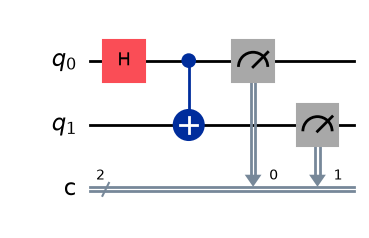

In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Create a 2-qubit circuit
qc = QuantumCircuit(2, 2)

# Hadamard gate
qc.h(0)

# CNOT gate
qc.cx(0, 1)

# Measurement
qc.measure([0, 1], [0, 1])

# Display circuit
display(qc.draw("mpl"))

Measurement counts: {'00': 514, '11': 510}


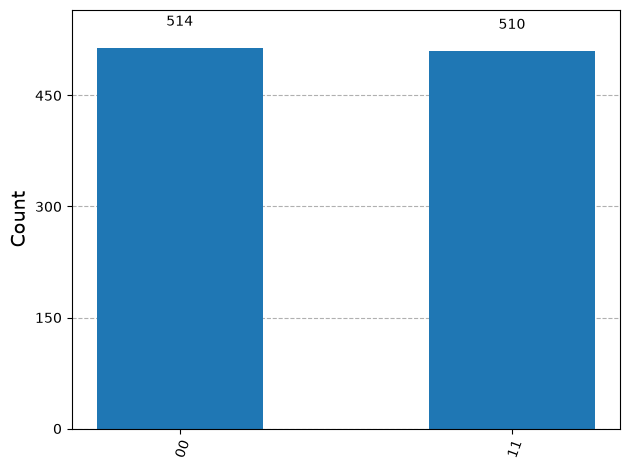

In [ ]:
simulator = AerSimulator()

job = simulator.run(qc, shots=1024)
result = job.result()

counts = result.get_counts()

print("Measurement counts:", counts)

display(plot_histogram(counts))


### 4.1 Local Simulation Results

The circuit was simulated using the AerSimulator with 1024 measurement shots.

The observed counts were:

- 00: 514
- 11: 510

Only the two expected outcomes, 00 and 11, were obtained. Their nearly equal counts agree with the theoretical probability of 0.5 for each outcome.

This result demonstrates the expected measurement statistics of the ideal Bell-state circuit.


In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService

# IBM Quantum credentials are stored locally.
# Do not include API keys or private credentials in this notebook.

service = QiskitRuntimeService()
print("Connected to IBM Quantum!")

In [ ]:
backends = service.backends(
    operational=True,
    simulator=False
)

print("Available IBM Quantum hardware:\n")

for backend in backends:
    print(
        "Backend:", backend.name,
        "| Qubits:", backend.num_qubits
    )

Available IBM Quantum hardware:

Backend: ibm_fez | Qubits: 156
Backend: ibm_kingston | Qubits: 156
Backend: ibm_marrakesh | Qubits: 156


In [ ]:
backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=2
)

print("Selected backend:", backend.name)
print("Number of qubits:", backend.num_qubits)

Selected backend: ibm_marrakesh
Number of qubits: 156



The least_busy() method was used to select an operational quantum processor with at least two qubits. The selected backend for this experiment was ibm_marrakesh, which has 156 qubits.


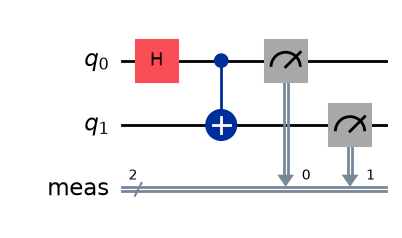

In [ ]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

# Define quantum and classical registers
qr = QuantumRegister(2, name="q")
meas = ClassicalRegister(2, name="meas")

# Create the circuit
qc = QuantumCircuit(qr, meas)

# Hadamard gate
qc.h(0)

# CNOT gate
qc.cx(0, 1)

# Measurement
qc.measure(qr, meas)

# Display circuit
display(qc.draw("mpl"))

Hardware-compatible circuit:


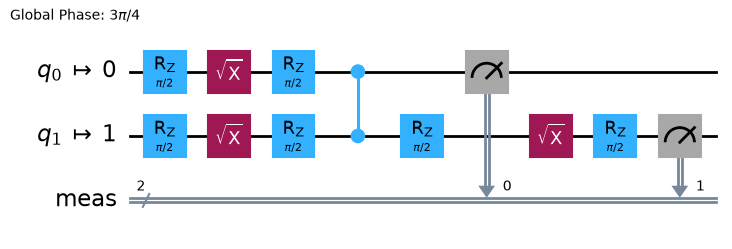

In [ ]:
from qiskit.transpiler import generate_preset_pass_manager

pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=1
)

isa_circuit = pm.run(qc)

print("Hardware-compatible circuit:")
display(isa_circuit.draw("mpl"))

In [ ]:
from qiskit_ibm_runtime.executor_sampler import Sampler

sampler = Sampler(mode=backend)

job = sampler.run(
    [isa_circuit],
    shots=1024
)

print("Job submitted successfully!")
print("Backend:", backend.name)
print("Job ID:", job.job_id())
print("Job status:", job.status())

Job submitted successfully!
Backend: ibm_marrakesh
Job ID: dbqan7ok09pc73astnc0
Job status: QUEUED


In [ ]:
print("Job status:", job.status())

Job status: DONE


In [ ]:
result = job.result()

pub_result = result[0]

counts = pub_result.data.meas.get_counts()

print("Hardware measurement counts:")
print(counts)

Hardware measurement counts:
{'11': 454, '01': 30, '00': 525, '10': 15}


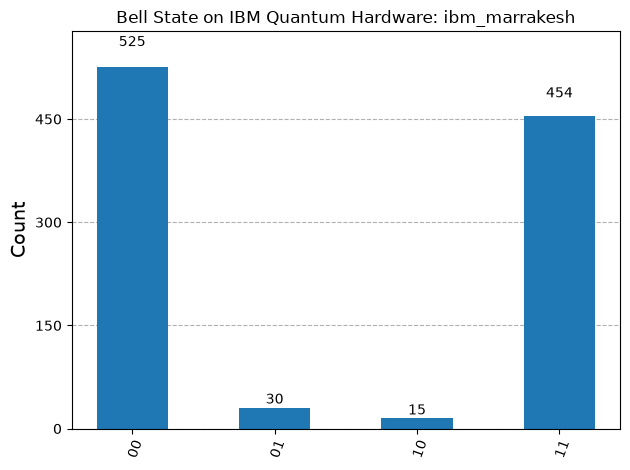

In [ ]:
from qiskit.visualization import plot_histogram

display(plot_histogram(
    counts,
    title=f"Bell State on IBM Quantum Hardware: {backend.name}"
))


### 5.1 IBM Quantum Hardware Results

The Bell-state circuit was executed on the IBM Marrakesh quantum processor using 1024 shots.

The observed measurement counts were:

| Measurement | Counts | Percentage |
|---|---:|---:|
| 00 | 525 | 51.27% |
| 01 | 30 | 2.93% |
| 10 | 15 | 1.46% |
| 11 | 454 | 44.34% |

The outcomes 00 and 11 together account for 95.61% of the measurements. The remaining 4.39% correspond to 01 and 10.

Unlike the ideal simulator, real quantum hardware is affected by imperfections in gate operations, decoherence and measurement. These effects can produce outcomes that are not expected in the ideal circuit.

The results show strong correlations between the measurement outcomes of the two qubits. However, this computational-basis measurement alone does not establish the fidelity of the prepared Bell state.



## 6. Conclusion

In this experiment, a two-qubit Bell state was successfully prepared and simulated using Qiskit Aer. The same circuit was subsequently executed on the IBM Marrakesh quantum processor.

The ideal simulation produced only the outcomes 00 and 11, with nearly equal frequencies. The real hardware experiment also showed these two outcomes as the dominant measurement results, but a small number of 01 and 10 outcomes were observed.

The difference between the two results illustrates the effect of imperfections in real quantum hardware.

This experiment provides a practical introduction to quantum circuit construction, local simulation, hardware-specific transpilation and execution on a real quantum processor.



## 7. Software and Platform

- Python 3.11
- Qiskit 2.6.2
- Qiskit Aer 0.18.2
- Qiskit IBM Runtime 0.52.0
- Matplotlib 3.11.2
- IBM Quantum hardware: ibm_marrakesh
- Number of measurement shots: 1024
